Page numbers are the printed pages of University Physics Vol. 1 and Vol. 2 in 00_books. In the PDF, add 12 (p. 572 is PDF page 584).

## Exercise 1: Rotating coil generator

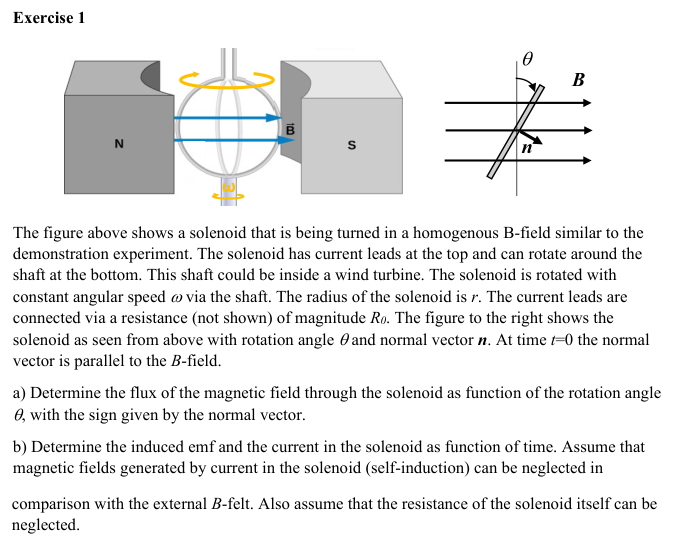

Book: University Physics Vol. 2, Section 13.1 Faraday's Law and Section 13.6 Electric Generators and Back Emf.

1. Flux, Eq. 13.1 (p. 547): $\Phi_m = \int \vec B\cdot\hat n\,dA$. The field is uniform and the coil is flat, so one turn gives $BA\cos\theta$, where $\theta$ is the angle between $\hat n$ and $\vec B$.
2. Faraday's law for $N$ turns, Eq. 13.3 (p. 548): $\varepsilon = -N\,d\Phi_m/dt$. With $\theta = \omega t$ this is the generator result, Eq. 13.16 (p. 572).
3. Ohm's law, Eq. 9.8 (p. 375): $I = \varepsilon/R_0$ (coil resistance and self-induction are neglected).

The sheet only gives the radius $r$, so the coil has area $A = \pi r^2$ and $N$ turns ($N = 1$ for a single loop).
Positive emf and current circulate counterclockwise around $\hat n$ (right-hand rule), the same convention that fixes the sign of $\Phi$.

a) Total flux through the $N$ turns:

$$\Phi(\theta) = N B \pi r^2 \cos\theta$$

Positive at $\theta = 0$ ($\hat n \parallel \vec B$), zero at $90°$, most negative at $180°$.

b) With $\theta = \omega t$:

$$\varepsilon(t) = -\frac{d\Phi}{dt} = N B \pi r^2\,\omega \sin(\omega t), \qquad I(t) = \frac{N B \pi r^2\,\omega}{R_0}\sin(\omega t)$$

The emf is largest at $\theta = 90°$, where the flux passes through zero and changes fastest.

## Exercise 1, c) to f)

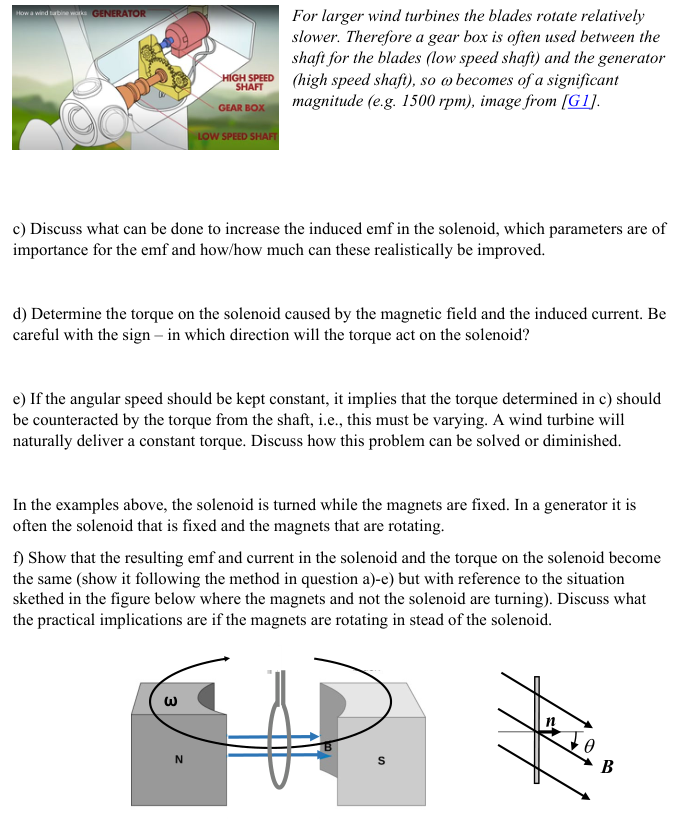

Book: University Physics Vol. 2.

1. Torque on a coil, Eq. 11.21 and 11.22 (p. 480 to 481): $\vec\mu = NIA\,\hat n$ and $\vec\tau = \vec\mu\times\vec B$, with size $\mu B\sin\theta$.
2. Lenz's law (Section 13.2, p. 550): the induced current opposes the change that causes it, so the torque must brake the rotation.
3. The induced emf depends only on the relative motion of magnet and coil (p. 546). This is the key to f).

Sign: torque is counted along $\vec\omega$, so a positive torque speeds the coil up.

The code below only illustrates d) and e). The numbers are assumptions (not in the sheet): $N = 100$, $r = 5$ cm, $B = 1.0$ T, $R_0 = 10\ \Omega$ and 1500 rpm as in the sheet.

peak emf = 123 V,  peak current = 12.3 A
one coil:    torque between -9.69 and 0 N m, mean -4.84 N m
three coils: total torque between -14.5 and -14.5 N m
power check: largest |tau*w + emf*I| = 4.5e-13 W


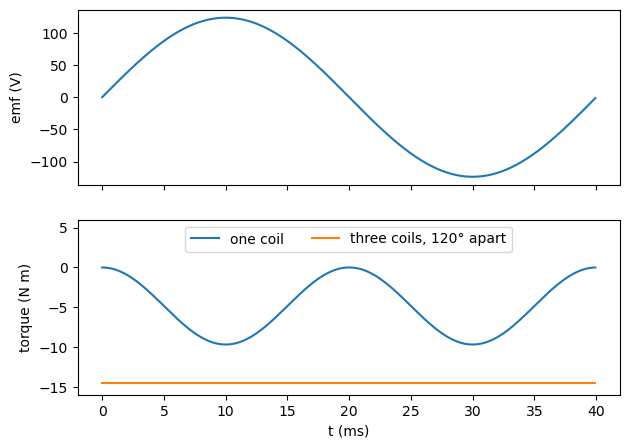

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

N = 100                         # turns (assumed)
r = 0.05                        # m (assumed)
B = 1.0                         # T (assumed, NdFeB)
w = 1500 * 2 * math.pi / 60     # rad/s, 1500 rpm
R0 = 10                         # ohm (assumed)

A = math.pi * r**2
t = np.linspace(0, 2 * math.pi / w, 600, endpoint=False)

emf = N * B * A * w * np.sin(w * t)
I = emf / R0
tau = -(N * B * A)**2 * w * np.sin(w * t)**2 / R0

# three coils 120 degrees apart (three-phase)
tau3 = sum(-(N * B * A)**2 * w * np.sin(w * t - k * 2 * math.pi / 3)**2 / R0 for k in range(3))

print(f"peak emf = {emf.max():.3g} V,  peak current = {I.max():.3g} A")
print(f"one coil:    torque between {tau.min():.3g} and 0 N m, mean {tau.mean():.3g} N m")
print(f"three coils: total torque between {tau3.min():.3g} and {tau3.max():.3g} N m")
print(f"power check: largest |tau*w + emf*I| = {np.abs(tau * w + emf * I).max():.1e} W")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
ax1.plot(t * 1e3, emf)
ax1.set_ylabel("emf (V)")
ax2.plot(t * 1e3, tau, label="one coil")
ax2.plot(t * 1e3, tau3, label="three coils, 120° apart")
ax2.set_xlabel("t (ms)")
ax2.set_ylabel("torque (N m)")
ax2.set_ylim(-16, 6)
ax2.legend(loc="upper center", ncol=2)
plt.show()

c) The peak emf is $\varepsilon_0 = NBA\omega$, Eq. 13.18 (p. 572), so it grows in proportion to each factor:
- $N$: more turns, but in a fixed space the wire gets longer and thinner, so the coil resistance and copper losses grow quickly. Copper volume and cost set the limit.
- $B$: NdFeB magnets give about 1 T in the gap and iron saturates near 2 T, so at most about a factor 2 is left.
- $A$: a bigger coil needs more magnet material to keep $B$ over the whole area (the sheet says about 1 ton of magnets per MW) and a bigger, heavier machine.
- $\omega$: the gearbox raises the blade speed (assumed 10 to 20 rpm) to about 1500 rpm, roughly a factor 100 and the biggest gain. It is limited by gearbox wear, losses and stress. Direct-drive turbines skip the gearbox and use a large diameter with many magnet poles instead.

d) With $\mu = NIA$ and $I$ from b):

$$\tau(t) = -\frac{(N B \pi r^2)^2\,\omega}{R_0}\sin^2(\omega t)$$

Sign: for $0 < \theta < 180°$, $I > 0$ so $\vec\mu$ points along $\hat n$, and $\vec\mu\times\vec B$ turns $\hat n$ back toward $\vec B$, against $\vec\omega$. In the second half turn $I$ and $\sin\theta$ both flip, so the torque always brakes the coil (Lenz).
Check: $-\tau\omega = \varepsilon^2/R_0 = I^2R_0$, so the shaft work becomes heat in $R_0$ (the power check in the code gives zero up to rounding).

e) (The sheet says "the torque determined in c)", it means d).) One coil gives a torque that pulses between 0 and its peak at twice the rotation frequency. Real generators use three coils 120° apart (three-phase): since $\sin^2\theta + \sin^2(\theta - 120°) + \sin^2(\theta + 120°) = 3/2$, the total torque is constant (flat line in the plot). Any remaining ripple is smoothed by the large moment of inertia of the rotor and blades, which act as a flywheel.

f) Now the coil is fixed and the field turns, but the angle between $\hat n$ and $\vec B$ is still $\theta = \omega t$. The flux depends only on this angle, so $\Phi = NB\pi r^2\cos(\omega t)$ as in a), and the emf and current are the same as in b). The torque on the coil has the same size $(NB\pi r^2)^2\omega\sin^2(\omega t)/R_0$, but it now pulls the coil along with the turning field, so the coil must be held; by Newton's third law the magnets get the opposite torque, which brakes them exactly as the coil was braked in d).
Practical: the coil that carries the current stands still, so no slip rings and brushes (Fig. 13.29, p. 572) are needed. There are no sliding contacts to wear or spark, and the heavy high-current coils can be bolted to the housing and cooled easily.

## Exercise 2: Bicycle light

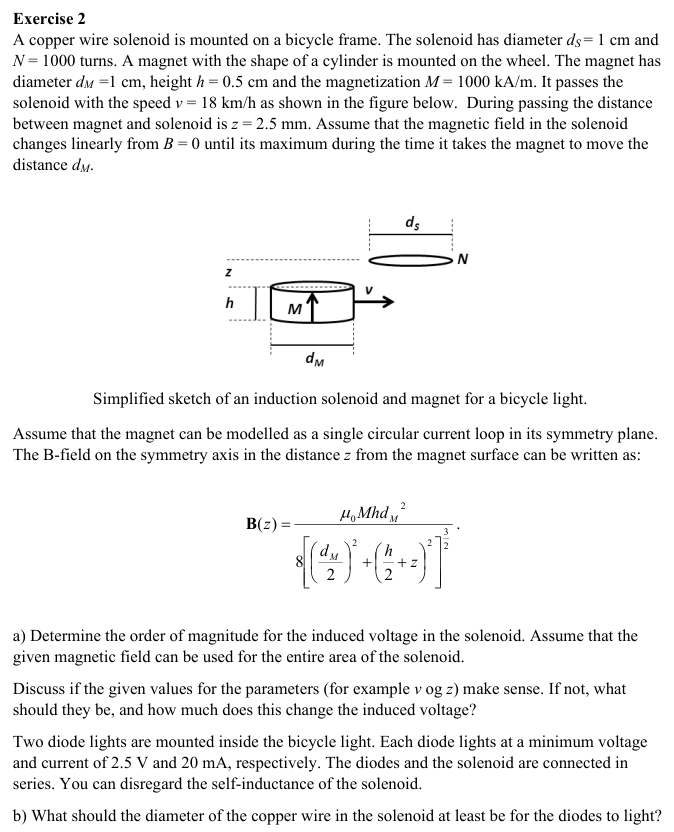

Book: University Physics Vol. 2.

1. The given $B(z)$ is the field on the axis of a current loop, Eq. 12.15 (p. 513), with loop current $Mh$, radius $d_M/2$ and distance $h/2 + z$ from the loop.
2. Faraday's law, Eq. 13.3 (p. 548): $|\varepsilon| = N A_S\,\Delta B/\Delta t$, with $\Delta B = B(z)$ (from 0), $\Delta t = d_M/v$ (the sheet's linear assumption) and $A_S = \pi(d_S/2)^2$.
3. Series circuit: the emf must cover both diodes and the wire, $\varepsilon \ge 2 \cdot 2.5\text{ V} + I R_{wire}$ with $I = 20$ mA. Wire resistance, Eq. 9.9 (p. 376): $R_{wire} = \rho L/A_{wire}$ with $L = N\pi d_S$ and $\rho_{Cu} = 1.68\cdot10^{-8}\ \Omega$ m (Table 9.1, p. 373).

In [2]:
import math

mu0 = 4 * math.pi * 1e-7    # T m/A
M = 1000e3                  # A/m
h = 0.005                   # m
dM = 0.01                   # m
z = 0.0025                  # m
dS = 0.01                   # m
N = 1000                    # turns
v = 18 / 3.6                # m/s

def B(z):
    return mu0 * M * h * dM**2 / (8 * ((dM / 2)**2 + (h / 2 + z)**2)**1.5)

AS = math.pi * (dS / 2)**2
emf = N * AS * B(z) / (dM / v)
print(f"a) B = {B(z):.3g} T,  dt = {dM / v * 1e3:.3g} ms,  emf = {emf:.3g} V")

# more realistic: magnet on the spokes at about 1/3 of the wheel radius (assumption)
v_mag = v / 3
emf_real = N * AS * B(z) / (dM / v_mag)
print(f"   magnet speed {v_mag * 3.6:.3g} km/h: emf = {emf_real:.3g} V")
print(f"   gap z = 5 mm instead of 2.5 mm: B = {B(0.005):.3g} T")

rho = 1.68e-8               # ohm m, copper
V_diodes = 2 * 2.5          # V
I = 0.020                   # A

L = N * math.pi * dS
R_max = (emf - V_diodes) / I
A_wire = rho * L / R_max
d_wire = math.sqrt(4 * A_wire / math.pi)
print(f"b) L = {L:.3g} m,  R_wire <= {R_max:.3g} ohm,  d_wire >= {d_wire * 1e3:.3g} mm")
print(f"   at the realistic magnet speed: N >= {V_diodes / (emf_real / N):.0f} turns just to reach 5 V")

a) B = 0.222 T,  dt = 2 ms,  emf = 8.72 V
   magnet speed 6 km/h: emf = 2.91 V
   gap z = 5 mm instead of 2.5 mm: B = 0.107 T
b) L = 31.4 m,  R_wire <= 186 ohm,  d_wire >= 0.0601 mm
   at the realistic magnet speed: N >= 1719 turns just to reach 5 V


a) $B \approx 0.22$ T at the coil, $\Delta t = 2$ ms, so $\varepsilon \approx 8.7$ V: order of magnitude 10 V.

- $M$: $\mu_0 M = 1.26$ T is typical for NdFeB, so this is fine.
- $z = 2.5$ mm is realistic: the gap must be a few mm so the wheel can wobble. $B$ drops quickly with $z$ (5 mm halves it).
- $v = 18$ km/h is a normal cycling speed, but only the rim moves that fast relative to the frame. The magnets sit on the spokes near the hub, at about 1/3 of the wheel radius (assumption: about 11 cm from the axle on a wheel of radius about 33 cm), so they pass the coil at about 6 km/h. Since $\varepsilon \propto v$, this gives $\varepsilon \approx 2.9$ V, order 1 V instead of 10 V.

b) With the given values ($\varepsilon \approx 8.7$ V): $R_{wire} \le 186\ \Omega$ for $L = 31.4$ m of wire, so the wire diameter must be at least about 0.06 mm.

With the realistic magnet speed the emf (2.9 V) is below the 5 V the two diodes need, so they do not light at 18 km/h for any wire thickness. The design then needs more turns (at least about 1700, since $\varepsilon \propto N$), a smaller gap, or magnets farther out on the spokes.

## Exercise 3: DC motor

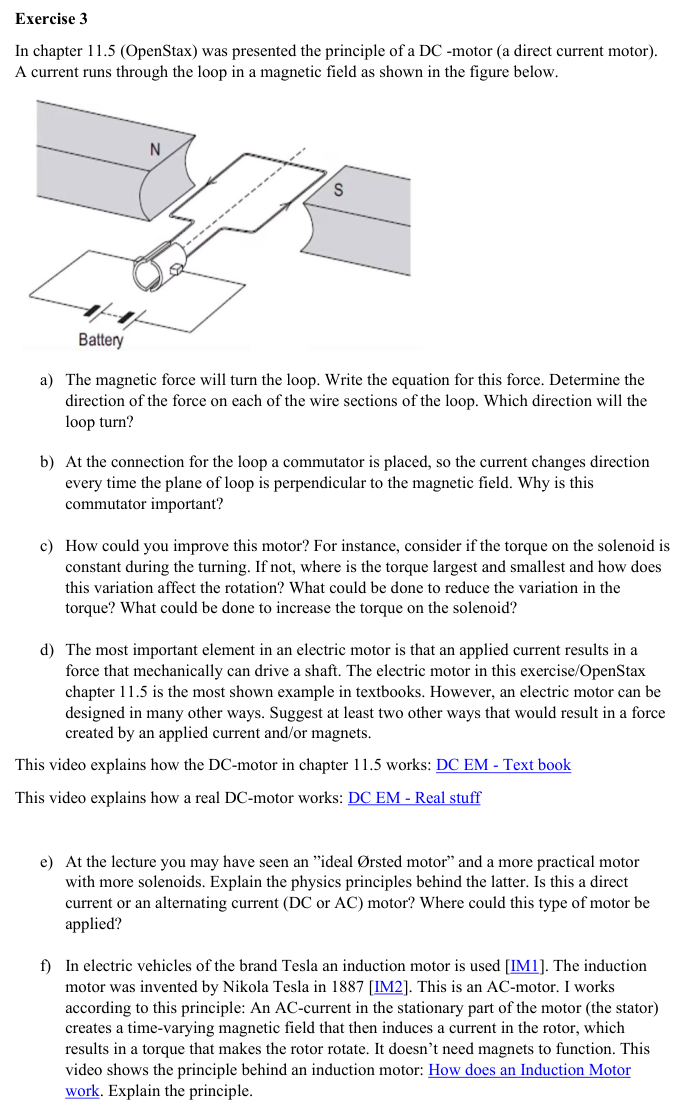

Book: University Physics Vol. 2.

1. Force on a straight wire, Eq. 11.13 (p. 476): $\vec F = I\vec l\times\vec B$, direction by RHR-1.
2. Torque on a loop, Eq. 11.19 and 11.22 (p. 480 to 481): $\tau = NIAB\sin\theta$, with $\theta$ between $\vec\mu$ and $\vec B$. The DC motor and its commutator are Fig. 11.15 (p. 479).

From the figure: $\vec B$ points from N (left) to S (right). The current runs along the side next to S away from the commutator, crosses over at the far end, and comes back along the side next to N toward the commutator. The short sides run parallel to $\vec B$.

a) $\vec F = I\vec L\times\vec B$, size $ILB$ on each long side.
- Side next to N (current toward the commutator): force up.
- Side next to S (current away from the commutator): force down.
- Short sides: parallel to $\vec B$, no force.

The loop turns clockwise as seen from the commutator end (N side up, S side down).

b) Without it, once the loop passes the position where its plane is perpendicular to $\vec B$, the torque reverses and pulls it back, so the loop only swings about that position and stops. Reversing the current every half turn flips $\vec\mu$, so the torque keeps the same sign and the loop keeps turning.

c) The torque is not constant: $\tau = NIAB\sin\theta$ is largest when the plane of the loop is parallel to $\vec B$ (as drawn) and zero when it is perpendicular (where the commutator switches). The loop speeds up and slows down every half turn, and it cannot start from a dead spot. Several coils at different angles, each with its own commutator segments, make the total torque nearly constant (the book mentions three contact areas to avoid dead spots, p. 479). For more torque: more turns $N$, more current $I$, larger area $A$, stronger $B$ (NdFeB magnets, an iron core in the coil).

d) For example:
- Linear motor: coils carrying current in a magnetic field get $\vec F = I\vec L\times\vec B$ along a straight track (maglev trains, rail guns).
- Homopolar motor: a current flows radially through a disc on a magnet; the force is tangential, so the disc spins without any commutator.
- Solenoid (reluctance) actuator: a coil pulls an iron plunger into itself (door locks, the starter solenoid in a car).

e) Several solenoids sit around a permanent-magnet rotor. A current in a solenoid makes a magnetic field, and the rotor magnet feels a torque $\vec\mu\times\vec B$ toward that field. Switching the solenoids on one after another moves the field around ahead of the magnet, so the rotor keeps following it. It is fed with DC and the switching is done by a commutator or by electronics with a position sensor (a brushless DC motor), even though each coil sees current pulses that alternate like AC. Uses: computer fans, drones, e-bikes, stepper motors in 3D printers, and many electric cars.

f) Three-phase AC currents in stator coils placed 120° apart add up to a magnetic field of constant size that rotates at the supply frequency. The rotor is a cage of conducting bars with no magnets. The rotating field changes the flux through the rotor loops, so emf and currents are induced (Faraday), and by Lenz's law they oppose the relative motion: the force $I\vec L\times\vec B$ drags the rotor along with the field. The rotor always turns slightly slower than the field (slip), because at the same speed there would be no flux change, no current and no torque.